In [1]:
import pandas as pd
import numpy as np

print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:
import os

os.chdir(r"C:\Users\Girish\Predictive_Churn_Analysis")

print("Current folder:", os.getcwd())
print("Files:", os.listdir())

Current folder: C:\Users\Girish\Predictive_Churn_Analysis
Files: ['.ipynb_checkpoints', 'customer_churn_model_v2.csv']


In [5]:
import pandas as pd
import numpy as np

df = pd.read_csv("customer_churn_model_v2.csv")

print("Dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

display(df.head())

Dataset loaded successfully!
Number of rows: 800
Number of columns: 13


,CustomerID,Age,Region,TenureMonths,SubscriptionType,MonthlyChargesINR,TotalChargesINR,ContractType,SupportTickets,LatePayments,PaymentMethod,AutoPay,Churn
0,CUST-100001,57,South,33,Standard,767.25,23893.97,Month-to-Month,4,1,UPI,Yes,Yes
1,CUST-100002,44,South,45,Basic,476.72,21627.46,Two Year,0,1,UPI,Yes,Yes
2,CUST-100003,64,South,57,Basic,414.81,22500.07,One Year,1,1,UPI,No,Yes
3,CUST-100004,57,East,44,Pro,1171.76,50309.16,Month-to-Month,4,0,Card,Yes,Yes
4,CUST-100005,58,North,49,Pro,1130.19,55980.21,Month-to-Month,3,0,Wallet,No,No


In [6]:
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

Column names:
['CustomerID', 'Age', 'Region', 'TenureMonths', 'SubscriptionType', 'MonthlyChargesINR', 'TotalChargesINR', 'ContractType', 'SupportTickets', 'LatePayments', 'PaymentMethod', 'AutoPay', 'Churn']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         800 non-null    object 
 1   Age                800 non-null    int64  
 2   Region             800 non-null    object 
 3   TenureMonths       800 non-null    int64  
 4   SubscriptionType   800 non-null    object 
 5   MonthlyChargesINR  800 non-null    float64
 6   TotalChargesINR    800 non-null    float64
 7   ContractType       800 non-null    object 
 8   SupportTickets     800 non-null    int64  
 9   LatePayments       800 non-null    int64  
 10  PaymentMethod      800 non-null    object 
 11  AutoPay            800 non-null    

In [7]:
print("Churn counts:")
print(df["Churn"].value_counts())

print("\nChurn percentages:")
print(df["Churn"].value_counts(normalize=True).mul(100).round(2))

Churn counts:
Churn
No     466
Yes    334
Name: count, dtype: int64

Churn percentages:
Churn
No     58.25
Yes    41.75
Name: proportion, dtype: float64


In [8]:
# Keep customer IDs separately for the final predictions
customer_ids = df["CustomerID"].copy()

# Separate input features and target
X = df.drop(columns=["CustomerID", "Churn"])
y = df["Churn"].map({"No": 0, "Yes": 1})

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget mapping:")
print("No churn = 0")
print("Churn = 1")

print("\nTarget values:")
print(y.value_counts())

Features shape: (800, 11)
Target shape: (800,)

Target mapping:
No churn = 0
Churn = 1

Target values:
Churn
0    466
1    334
Name: count, dtype: int64


In [9]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training samples: 640
Testing samples: 160

Training target distribution:
Churn
0    373
1    267
Name: count, dtype: int64

Testing target distribution:
Churn
0    93
1    67
Name: count, dtype: int64


In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, MinMaxScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Identify numerical and categorical features
numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

# Preprocess numerical features
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", MinMaxScaler())
])

# Preprocess categorical features
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine the preprocessing steps
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# Fit only on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Transform test data without refitting
X_test_processed = preprocessor.transform(X_test)

print("Preprocessing completed successfully!")
print("Training data shape:", X_train_processed.shape)
print("Testing data shape:", X_test_processed.shape)
print("\nNumerical features:", numeric_features)
print("Categorical features:", categorical_features)

Preprocessing completed successfully!
Training data shape: (640, 23)
Testing data shape: (160, 23)

Numerical features: ['Age', 'TenureMonths', 'MonthlyChargesINR', 'TotalChargesINR', 'SupportTickets', 'LatePayments']
Categorical features: ['Region', 'SubscriptionType', 'ContractType', 'PaymentMethod', 'AutoPay']


In [11]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced"
)

model.fit(X_train_processed, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [12]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

# Predict churn classes and probabilities
y_pred = model.predict(X_test_processed)
y_prob = model.predict_proba(X_test_processed)[:, 1]

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, y_pred, zero_division=0), 4))
print("F1-Score:", round(f1_score(y_test, y_pred, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["No Churn", "Churn"],
    zero_division=0
))

Accuracy: 0.6062
Precision: 0.5303
Recall: 0.5224
F1-Score: 0.5263
ROC-AUC: 0.6456

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.66      0.67      0.66        93
       Churn       0.53      0.52      0.53        67

    accuracy                           0.61       160
   macro avg       0.59      0.59      0.59       160
weighted avg       0.61      0.61      0.61       160



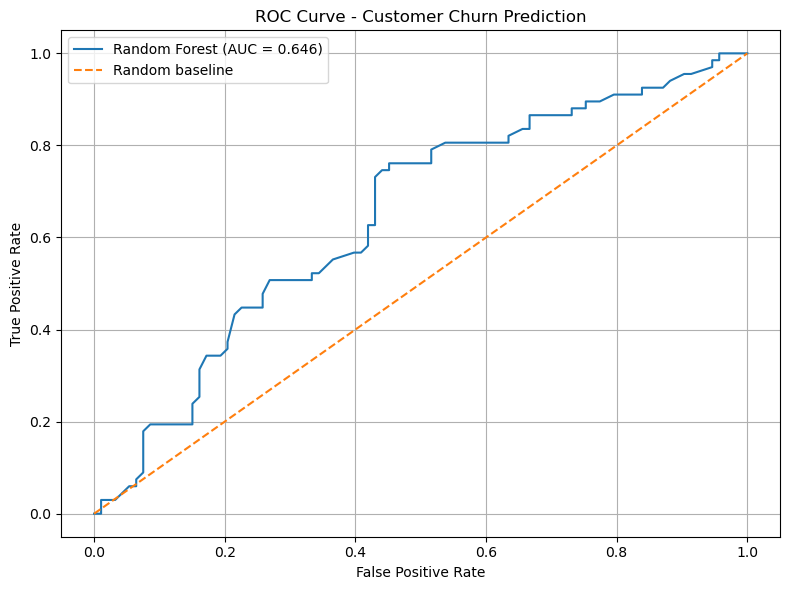

In [13]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

fpr, tpr, thresholds = roc_curve(y_test, y_prob)
roc_auc = roc_auc_score(y_test, y_prob)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f"Random Forest (AUC = {roc_auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random baseline")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Customer Churn Prediction")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [14]:
predictions = pd.DataFrame({
    "CustomerID": customer_ids.loc[X_test.index].values,
    "ActualChurn": y_test.map({0: "No", 1: "Yes"}).values,
    "PredictedChurn": pd.Series(y_pred, index=X_test.index)
        .map({0: "No", 1: "Yes"}).values,
    "ChurnProbability": y_prob
})

predictions = predictions.sort_values(
    "ChurnProbability",
    ascending=False
)

predictions.to_csv("churn_risk_predictions.csv", index=False)

print("Predictions exported successfully!")
display(predictions.head(10))

Predictions exported successfully!


,CustomerID,ActualChurn,PredictedChurn,ChurnProbability
79,CUST-100105,No,Yes,0.810
130,CUST-100519,Yes,Yes,0.805
4,CUST-100156,Yes,Yes,0.785
134,CUST-100439,No,Yes,0.765
65,CUST-100102,No,Yes,0.765
16,CUST-100172,No,Yes,0.760
82,CUST-100685,Yes,Yes,0.760
63,CUST-100598,No,Yes,0.755
93,CUST-100071,Yes,Yes,0.755
127,CUST-100514,No,Yes,0.740


In [15]:
import os
import pandas as pd

print("Current folder:", os.getcwd())

print("\nPrediction file exists:",
      os.path.exists("churn_risk_predictions.csv"))

if os.path.exists("churn_risk_predictions.csv"):
    predictions_check = pd.read_csv("churn_risk_predictions.csv")

    print("Number of predictions:", len(predictions_check))
    display(predictions_check.head())

Current folder: C:\Users\Girish\Predictive_Churn_Analysis

Prediction file exists: True
Number of predictions: 160


,CustomerID,ActualChurn,PredictedChurn,ChurnProbability
0,CUST-100105,No,Yes,0.810
1,CUST-100519,Yes,Yes,0.805
2,CUST-100156,Yes,Yes,0.785
3,CUST-100439,No,Yes,0.765
4,CUST-100102,No,Yes,0.765


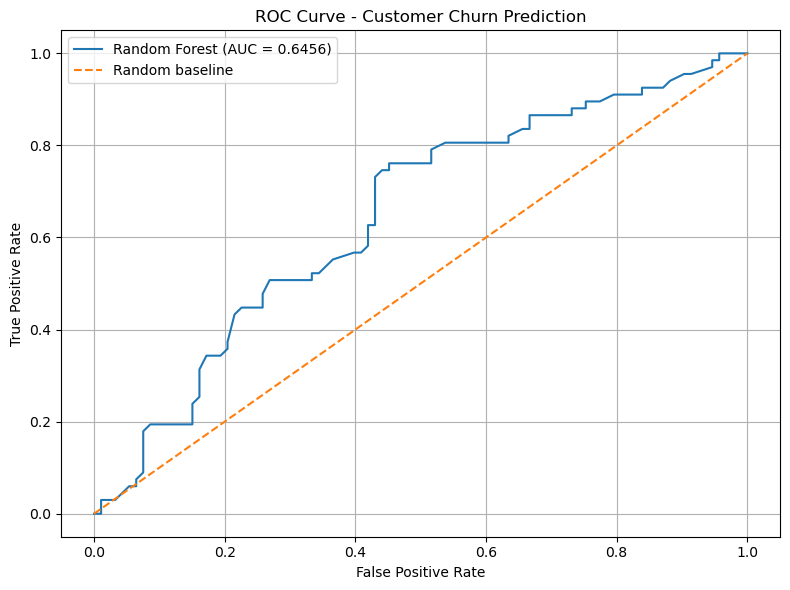

ROC curve saved successfully!
ROC-AUC: 0.6456


In [16]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score
import os

fpr, tpr, thresholds = roc_curve(y_test, y_prob)
roc_auc = roc_auc_score(y_test, y_prob)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f"Random Forest (AUC = {roc_auc:.4f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random baseline")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Customer Churn Prediction")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig("roc_curve.png", dpi=300, bbox_inches="tight")
plt.show()

print("ROC curve saved successfully!")
print("ROC-AUC:", round(roc_auc, 4))

In [17]:
report = f"""
PREDICTIVE CHURN ANALYSIS
=========================

1. PROJECT OBJECTIVE
The objective is to predict whether a customer will leave
a service using customer information.

2. DATASET
Dataset: customer_churn_model_v2.csv
Total customers: {len(df)}
Total columns: {df.shape[1]}
Input features used: {X.shape[1]}
Missing values: {df.isnull().sum().sum()}
Duplicate rows: {df.duplicated().sum()}

3. CHURN DISTRIBUTION
Customers who stayed: {(y == 0).sum()}
Customers who churned: {(y == 1).sum()}

4. DATA PREPROCESSING
- CustomerID excluded from model training.
- Churn encoded as 0 (No) and 1 (Yes).
- Categorical features processed using One-Hot Encoding.
- Numerical features scaled using MinMaxScaler.
- Dataset split into 80% training and 20% testing.
- Preprocessing fitted on training data only.

5. MACHINE LEARNING MODEL
Algorithm: Random Forest Classifier
Number of trees: 200
Random state: 42
Class weighting: Balanced

6. MODEL EVALUATION
Accuracy: {accuracy_score(y_test, y_pred):.4f}
Precision: {precision_score(y_test, y_pred, zero_division=0):.4f}
Recall: {recall_score(y_test, y_pred, zero_division=0):.4f}
F1-Score: {f1_score(y_test, y_pred, zero_division=0):.4f}
ROC-AUC: {roc_auc_score(y_test, y_prob):.4f}

7. CONCLUSION
The model demonstrates some ability to distinguish between
customers who churn and those who stay. Its performance
can be investigated further through model comparison,
feature analysis, and hyperparameter tuning.

The evaluation results describe performance on the held-out
test dataset. Further validation is recommended before
using the model for actual business decisions.
"""

with open("churn_analysis_report.txt", "w", encoding="utf-8") as file:
    file.write(report)

print("Report saved successfully!")
print(report)

Report saved successfully!

PREDICTIVE CHURN ANALYSIS

1. PROJECT OBJECTIVE
The objective is to predict whether a customer will leave
a service using customer information.

2. DATASET
Dataset: customer_churn_model_v2.csv
Total customers: 800
Total columns: 13
Input features used: 11
Missing values: 0
Duplicate rows: 0

3. CHURN DISTRIBUTION
Customers who stayed: 466
Customers who churned: 334

4. DATA PREPROCESSING
- CustomerID excluded from model training.
- Churn encoded as 0 (No) and 1 (Yes).
- Categorical features processed using One-Hot Encoding.
- Numerical features scaled using MinMaxScaler.
- Dataset split into 80% training and 20% testing.
- Preprocessing fitted on training data only.

5. MACHINE LEARNING MODEL
Algorithm: Random Forest Classifier
Number of trees: 200
Random state: 42
Class weighting: Balanced

6. MODEL EVALUATION
Accuracy: 0.6062
Precision: 0.5303
Recall: 0.5224
F1-Score: 0.5263
ROC-AUC: 0.6456

7. CONCLUSION
The model demonstrates some ability to distinguish 

In [18]:
import os

print("PROJECT FILES")
print("=" * 40)

for filename in os.listdir():
    if filename.endswith((".ipynb", ".csv", ".png", ".txt")):
        print(filename)

PROJECT FILES
churn_analysis_report.txt
churn_risk_predictions.csv
customer_churn_model_v2.csv
roc_curve.png
